# Causal Analysis

In [1]:
def default_params(): 
    return {
        #CodeGEN, #CodeGPT, #bigcode_starcoder2-3b, codellama_CodeLlama-7b-hf, deepseek-ai_deepseek-coder-1.3b-base, JetBrains_Mellum-4b-base, stabilityai_stable-code-3b 
        'model' : 'bigcode_starcoder2-3b',
        'input_path': '/workspaces/mica/semeru-datasets/mica/causal_analysis',
        'cache_dir': '/workspaces/CodeSmells/datax/hugging_face_cache',
        'output_path' : '/workspaces/mica/data/causal_analysis_results',
        'causal_analysis': {
            #'common_causes': ['t_length_token','t_token_counts', 't_ast_levels', 't_n_ast_nodes', 't_n_ast_errors', 't_n_identifiers', 't_complexity', 't_nloc'],
            'common_causes': ['t_token_counts', 't_n_ast_nodes', 't_complexity', 't_nloc'],
            #'effect_modifiers' : ['e_token_counts', 'e_ast_levels', 'e_n_ast_nodes', 'e_n_ast_errors', 'e_n_identifiers', 'e_complexity', 'e_nloc'],
            'effect_modifiers' : [],
            'instruments' : []
        }
    }
params = default_params()

### Imports

In [2]:
import pandas as pd
import numpy as np
from dowhy import CausalModel
import dowhy.datasets
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import zscore
import json
import os
import scipy.stats as stats

In [3]:
import matplotlib.pyplot as plt

### Dataset loading

In [4]:
combined_control_df = pd.read_json(F"{params['input_path']}/{params['model']}/control.json")
treatment_control_df = pd.read_json(F"{params['input_path']}/{params['model']}/treatment.json")

In [5]:
combined_control_df['group'] = 'control'
treatment_control_df['group'] = 'treatment'

In [6]:
causal_hypothesis_df =  pd.concat([combined_control_df, treatment_control_df], ignore_index=True)

In [7]:
causal_hypothesis_df.columns

Index(['method_id', 'java_code', 'java_code_infered', 'loss', 'min_k', 'zlib',
       'relative_loss', 'relative_zlib', 'relative_min_k', 't_complexity',
       't_nloc', 't_token_counts', 't_ast_levels', 't_n_ast_nodes',
       't_n_ast_errors', 't_ast_errors', 't_n_identifiers', 't_identifiers',
       'e_complexity', 'e_nloc', 'e_token_counts', 'e_ast_levels',
       'e_n_ast_nodes', 'e_n_ast_errors', 'e_ast_errors', 'e_n_identifiers',
       'e_identifiers', 'group', 'model', 'rule_number'],
      dtype='object')

### Causal Modeling

In [8]:
class RefutationResult:
    def __init__(self, refutation_result=None, new_effect=None):
        self.refutation_result = refutation_result
        self.new_effect = new_effect

In [9]:
def compute_ATE_and_refute(causal_model, identified_estimand, method_name, method_params={}):
    try:
        estimate = causal_model.estimate_effect(identified_estimand, method_name, method_params = method_params, test_significance=True)
    except Exception as e:
        print(f"======= ERROR COMPUTING CE for {method_name}: {e} ============")
        return {'method_name': method_name, 
            'estimated_effect': None,
            'refutation_placebo_permute' : None, 
            'refutation_unobserved_confounder' : None, 
            'refutation_subset' : None}
    
    refutation_placebo_permute = RefutationResult()
    refutation_unobserved_confounder = RefutationResult()
    refutation_subset = RefutationResult()
    refutation_random_common_cause = RefutationResult()
    
    try:
        refutation_placebo_permute = causal_model.refute_estimate(
                identified_estimand, estimate, method_name="placebo_treatment_refuter", placebo_type="permute")
    except Exception as e:
        print(f"Error performing pacebo refutation - {e}")
    try: 
        refutation_unobserved_confounder = causal_model.refute_estimate(
                identified_estimand, estimate, method_name="add_unobserved_common_cause")
    except Exception as e:
        print(f"Error performing unobserved covariate refutation - {e}")
    try:
        refutation_subset = causal_model.refute_estimate(
                identified_estimand, estimate, method_name="data_subset_refuter")
    except Exception as e:
        print(f"Error performing subset refutation - {e}")
    try: 
        refutation_random_common_cause = causal_model.refute_estimate(
                identified_estimand, estimate, method_name="random_common_cause")
    except Exception as e:
        print(f"Error performing random covariate refutation - {e}")
    

    return {'method_name': method_name, 
            'estimated_effect': estimate.value,
            'refutation_random_common_cause' : {'result' : refutation_random_common_cause.refutation_result, 'new_effect': refutation_random_common_cause.new_effect},
            'refutation_placebo_permute' : {'result' : refutation_placebo_permute.refutation_result, 'new_effect': refutation_placebo_permute.new_effect}, 
            'refutation_unobserved_confounder' : {'result' : refutation_unobserved_confounder.refutation_result, 'new_effect': refutation_unobserved_confounder.new_effect}, 
            'refutation_subset' : {'result' : refutation_subset.refutation_result, 'new_effect': refutation_subset.new_effect},}

def compute_correlations(input_corr_data, outout_corr_data):
    pearson_corr =  stats.pearsonr(input_corr_data, outout_corr_data)
    spearman_corr = stats.spearmanr(input_corr_data, outout_corr_data)
    kendall_corr = stats.kendalltau(input_corr_data, outout_corr_data)
    return {'pearson_corr' : pearson_corr.statistic, 'spearman_corr' : spearman_corr.statistic, 'kendall_corr' : kendall_corr.statistic}

def compute_causal_effects(causal_model):
    causal_effects_df = pd.DataFrame(columns=['method_name', 'pearson_corr', 'spearman_corr', 'kendall_corr' ,'estimated_effect', 'refutation_placebo_permute', 'refutation_unobserved_confounder', 'refutation_subset'])
    ####### COMPUTE PEARSON
    #correlation_results = compute_correlations(list(causal_model._data[causal_model._common_causes].mean(axis=1)), list(causal_model._data[causal_model._outcome].mean(axis=1)))
    correlation_results = compute_correlations(causal_model._data['binary_treatment'].tolist(), list(causal_model._data[causal_model._outcome].mean(axis=1)))
    ####### COMPUTE ESTIMAND
    identified_estimand = causal_model.identify_effect(proceed_when_unidentifiable=True)
    ###### COMPUTE CAUSAL EFFECT - BACKDOOR - propensity_score_matching
    causal_effects_df.loc[len(causal_effects_df)] = {**correlation_results, **compute_ATE_and_refute(causal_model, identified_estimand, "backdoor.propensity_score_matching")}
    ###### COMPUTE CAUSAL EFFECT - BACKDOOR - propensity_score_stratification
    causal_effects_df.loc[len(causal_effects_df)] = {**correlation_results, **compute_ATE_and_refute(causal_model, identified_estimand, "backdoor.propensity_score_stratification")}
    ###### COMPUTE CAUSAL EFFECT - BACKDOOR - backdoor.propensity_score_weighting
    causal_effects_df.loc[len(causal_effects_df)] = {**correlation_results, **compute_ATE_and_refute(causal_model, identified_estimand, "backdoor.propensity_score_weighting")}
    ###### COMPUTE CAUSAL EFFECT - BACKDOOR - backdoor.propensity_score_weighting
    causal_effects_df.loc[len(causal_effects_df)] = {**correlation_results, **compute_ATE_and_refute(causal_model, identified_estimand, "backdoor.generalized_linear_model", method_params={"glm_family": sm.families.Gaussian()})}
    
    return causal_effects_df.dropna()


In [10]:
def compute_mia_causal_effects(causal_hypothesis_df, outcomes):
    causal_effect_dfs = []
    for rule_number in list(causal_hypothesis_df['rule_number'].unique()):
        print(f"=========== CAUSAL ANALYSIS FOR RULE-{rule_number}")
        #### EXTRACT RULE
        rule_df = causal_hypothesis_df[causal_hypothesis_df['rule_number']==rule_number].copy()
        rule_df['binary_treatment'] = rule_df['group'].map(lambda group: True if group !='control' else False)
        rule_df = rule_df.dropna()
        ### ZCORE FOR OUTCOMES
        #for outcome in outcomes: rule_df[outcome] = zscore(rule_df[outcome])
        ##### DEFINE CAUSAL MODEL
        causal_model = CausalModel(
            data = rule_df,
            treatment = ['binary_treatment'],
            outcome = outcomes,
            common_causes = params['causal_analysis']['common_causes'],
            effect_modifiers = params['causal_analysis']['effect_modifiers'],
            instruments = params['causal_analysis']['instruments'])
        ##### STORE RESULTS
        result_df = compute_causal_effects(causal_model)
        result_df['rule_number'] = rule_number
        causal_effect_dfs.append(result_df)
    return pd.concat(causal_effect_dfs, ignore_index=True)



In [11]:
def create_folder(path):
    if not os.path.exists(path):
        os.makedirs(path)

In [12]:
len(list(causal_hypothesis_df['rule_number'].unique()))

### EXECUTE

In [13]:
def execute_analysis(outcomes, causal_hypothesis_df):
    for outcome in outcomes:
        print(f"============================= COMPUTING ANALYSIS FOR OUTCOME-{outcome} ==================================== ")
        causal_effects_outcome_df = compute_mia_causal_effects(causal_hypothesis_df, [outcome])
        print(f"============================= STORING ANALYSIS FOR OUTCOME-{outcome} ==================================== ")
        output_path = f"{params['output_path']}/{params['model']}"
        create_folder(output_path)
        causal_effects_outcome_df.to_json(f"{output_path}/{[outcome]}.json")
    #print(f"============================= COMPUTING ANALYSIS FOR ALL OUTCOMES-{outcomes} ==================================== ")
    #causal_effects_outcome_df = compute_mia_causal_effects(causal_hypothesis_df, outcomes)
    #print(f"============================= STORING ANALYSIS FOR ALL OUTCOMES-{outcomes}==================================== ")
    #output_path = f"{params['output_path']}/{params['model']}"
    #create_folder(output_path)
    #causal_effects_outcome_df.to_json(f"{output_path}/{outcomes}.json")

In [14]:
list(causal_hypothesis_df['rule_number'].unique())

['rule_1',
 'rule_24',
 'rule_16',
 'rule_11',
 'rule_23',
 'rule_6',
 'rule_2',
 'rule_8',
 'rule_15',
 'rule_12',
 'rule_18',
 'rule_20',
 'rule_5',
 'rule_7',
 'rule_10',
 'rule_22',
 'rule_17',
 'rule_4',
 'rule_19',
 'rule_13',
 'rule_21',
 'rule_14',
 'rule_9',
 'rule_3']

============================= COMPUTING ANALYSIS FOR OUTCOME-loss ==================================== 
=========== CAUSAL ANALYSIS FOR RULE-rule_1


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.11/dist-packages/numpy/core/fromnumeric.py:3643: FutureWarning: The behavior of DataFrame.std with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return std(axis=axis, dtype=dtype, out=out, ddof=ddof, **kwargs)
/usr/local/lib/python3.11/dist-packages/dowhy/causal_refuters/add_unobserved_common_cause.py:321: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  std_dev_y = np.std(y)[0]
/usr/local/lib/python3.11/dist-

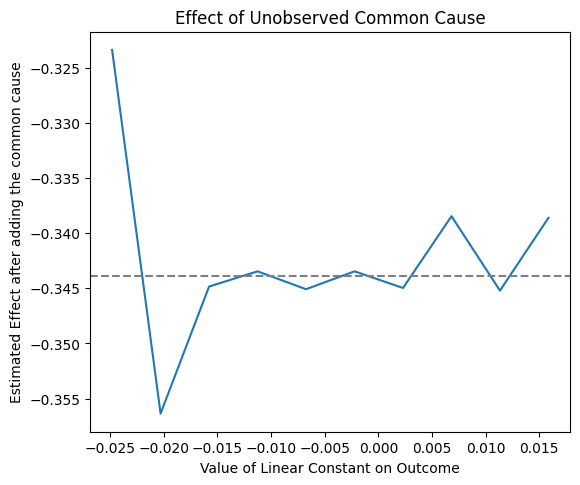

======= ERROR COMPUTING CE for backdoor.propensity_score_stratification: Not enough data to generate at least two strata. This error may be due to a high value of 'clipping_threshold'. ============


/tmp/ipykernel_207526/3994970460.py:62: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  causal_effects_df.loc[len(causal_effects_df)] = {**correlation_results, **compute_ATE_and_refute(causal_model, identified_estimand, "backdoor.propensity_score_stratification")}


KeyboardInterrupt: 

In [15]:
execute_analysis(['loss', 'min_k', 'zlib', 'relative_loss', 'relative_min_k', 'relative_zlib'], causal_hypothesis_df)